    Day  Sales
0     1    100
1     2    105
2     3    110
3     4    108
4     5    115
5     6    120
6     7    118
7     8    125
8     9    130
9    10    128
10   11    135
11   12    140
12   13    138
13   14    145
14   15    150
15   16    148
16   17    155
17   18    160
18   19    158
19   20    165


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.2519
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2100
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1743
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1407
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1091
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0828
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0584
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0379
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0223
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0125
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0088
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0071
Epoch 13/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0088
Epoch 14/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0098
Epoch 15/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0090
Epoch 16/50
4/4 ━━━━━━━━━━━━━━━━━━

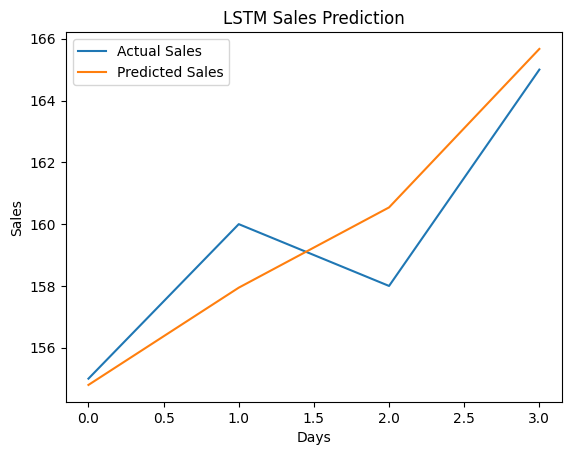

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Create dataset
data = {
    'Day': range(1, 21),
    'Sales': [
        100, 105, 110, 108, 115,
        120, 118, 125, 130, 128,
        135, 140, 138, 145, 150,
        148, 155, 160, 158, 165
    ]
}

df = pd.DataFrame(data)
print(df)

# Normalize sales values
scaler = MinMaxScaler()
sales = scaler.fit_transform(df[['Sales']])

# Prepare sequences
X = []
y = []

for i in range(3, len(sales)):
    X.append(sales[i-3:i])
    y.append(sales[i])

X = np.array(X)
y = np.array(y)

# Split data chronologically
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]
y_train = y[:split]
y_test = y[split:]

# Build LSTM model
model = Sequential([
    LSTM(50, activation='tanh', input_shape=(3, 1)),
    Dense(1)
])

# Compile model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=4,
    verbose=1
)

# Prediction
y_pred = model.predict(X_test)

# Convert predictions to original scale
y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred)

# Evaluation
print("Mean Absolute Error:",
      mean_absolute_error(y_test_actual, y_pred_actual))

print("Mean Squared Error:",
      mean_squared_error(y_test_actual, y_pred_actual))

print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test_actual, y_pred_actual)))

# Plot actual vs predicted sales
plt.plot(y_test_actual, label='Actual Sales')
plt.plot(y_pred_actual, label='Predicted Sales')
plt.xlabel('Days')
plt.ylabel('Sales')
plt.title('LSTM Sales Prediction')
plt.legend()
plt.show()
